In [3]:
import pandas as pd

In [5]:
import numpy as np

In [7]:
import matplotlib.pyplot as plt

# Read Files

In [8]:
df_participant = pd.read_csv('Participant.csv')

In [11]:
df_participant

,participantID,name,height,weight,gender,dominantHand,experience,notes
0,P1,George,72,190.0,Male,R,5,tested in morning
1,P2,Maria,65,145.0,Female,L,3,NaN
2,P3,Jordan,168,175.0,Unknown,R,4,missing height
3,P4,Alex,68,199.0,Male,R,2,NaN
4,P5,Sam,168,185.5,Unknown,L,4,formatting issue
5,P6,Chris,70,165.0,Female,R,4,NaN
6,P7,Taylor,64,135.0,Female,L,1,NaN
7,P8,Jamie,69,180.0,Male,R,6,NaN
8,P9,Morgan,67,185.5,Unknown,R,5,NaN
9,P10,Casey,161,150.0,Female,L,2,NaN


In [13]:
df_trial = pd.read_csv('Trial.csv')
df_song = pd.read_csv('Song.csv')



In [15]:
df_trial

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce
0,T1,P1,1,No music,100,25,5.1,150,50,90
1,T1,P1,2,No music,105,27,5.4,155,52,93
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108
5,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112
6,T6,P6,1,120+ BPM,125,35,7.0,185,70,125
7,T6,P6,2,120+ BPM,130,36,7.2,190,72,128
8,T7,P7,1,60-120 BPM,99,21,4.9,145,48,84
9,T7,P7,2,60-120 BPM,101,23,5.2,149,50,86


In [17]:
df_song

,songID,songName,bpmRange,bpm
0,S1,Expresso,90,60-120 BPM
1,S2,Believer,120,60-120 BPM
2,S3,Eye of the Tiger,150,120+ BPM
3,S4,Thunder,80,60-120 BPM
4,S5,Lose Yourself,123,120+ BPM
5,S6,Don't Stop Me Now,170,120+ BPM
6,S7,Levels,128,120+ BPM
7,S8,Sweet Child O' Mine,95,60-120 BPM
8,S9,Radioactive,105,60-120 BPM
9,S10,Uptown Funk,115,60-120 BPM


In [19]:
df_song_and_trial=pd.DataFrame()

# Join song table and trial table

In [34]:
df_song_and_trial = pd.merge(
    df_trial,
    df_song,
    on="bpm",
    how="inner"
)

In [36]:
df_song_and_trial

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,songID,songName,bpmRange
0,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S1,Expresso,90
1,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S2,Believer,120
2,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S4,Thunder,80
3,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S8,Sweet Child O' Mine,95
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S9,Radioactive,105
5,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,S10,Uptown Funk,115
6,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S1,Expresso,90
7,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S2,Believer,120
8,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S4,Thunder,80
9,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,S8,Sweet Child O' Mine,95


## Check if there are any duplicate


In [39]:
df_song_and_trial.duplicated()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
dtype: bool

## Read the Pivot files

In [41]:
df_bpm = pd.read_csv('bpm_pivot.csv')
df_attempt=pd.read_csv('attempt_pivot.csv')
df_bpm

,bpm,SUM of totalPunches,SUM of accuracy,SUM of maxForce,SUM of minForce,SUM of avgForce
0,<60 BPM,46,11.0,300,108,195
1,120+ BPM,71,14.2,375,142,253
2,60-120 BPM,105,22.6,631,220,390
3,No music,52,10.5,305,102,183
4,Grand Total,274,58.3,1611,572,1021


**This is used to get rid of the Grand Total**

In [43]:

df_bpm=df_bpm.iloc[:-1]
df_bpm

,bpm,SUM of totalPunches,SUM of accuracy,SUM of maxForce,SUM of minForce,SUM of avgForce
0,<60 BPM,46,11.0,300,108,195
1,120+ BPM,71,14.2,375,142,253
2,60-120 BPM,105,22.6,631,220,390
3,No music,52,10.5,305,102,183


In [45]:
len(df_bpm)

4

In [47]:
df_bpm.index

RangeIndex(start=0, stop=4, step=1)

## Building chart for Total Punches & Accuracy by BPM Range

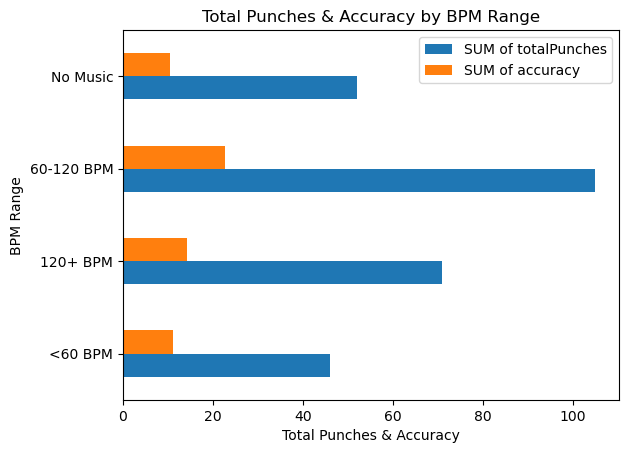

In [49]:
import matplotlib.pyplot as plt

df_chart_bpm = df_bpm[['SUM of totalPunches', 'SUM of accuracy']].plot.barh(
    xlabel="Total Punches & Accuracy",
    ylabel="BPM Range",
    title="Total Punches & Accuracy by BPM Range"
)

df_chart_bpm.set_yticks(range(4))
df_chart_bpm.set_yticklabels([
    '<60 BPM',
    '120+ BPM',
    '60-120 BPM',
    'No Music'
])

plt.show()

## Building chart for Total Punches & Accuracy by Attempt

In [53]:
df_attempt=df_attempt.iloc[:-1]
df_attempt

,attempt,SUM of totalPunches,SUM of accuracy,SUM of maxForce,SUM of minForce,SUM of avgForce
0,1,132,29.1,798,287,495
1,2,142,29.2,813,285,526


[Text(0, 0, '1'), Text(0, 1, '2')]

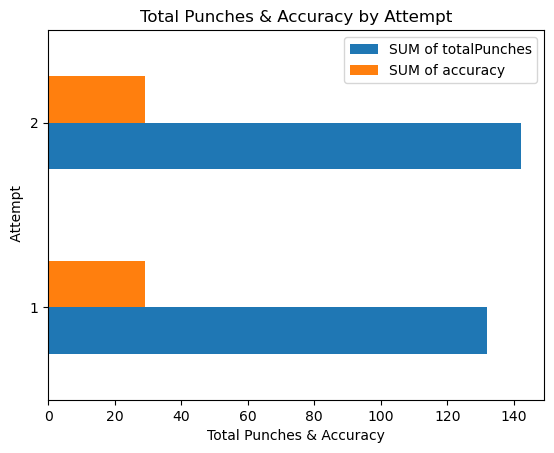

In [55]:
df_chart_attempt=df_attempt[['SUM of totalPunches','SUM of accuracy']].plot.barh(
        xlabel= "Total Punches & Accuracy",
        ylabel=" Attempt",
        title="Total Punches & Accuracy by Attempt"
)
df_chart_attempt.set_yticks(range(2))
df_chart_attempt.set_yticklabels(['1','2'])

## Trial Table


In [59]:
df_trial

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce
0,T1,P1,1,No music,100,25,5.1,150,50,90
1,T1,P1,2,No music,105,27,5.4,155,52,93
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108
5,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112
6,T6,P6,1,120+ BPM,125,35,7.0,185,70,125
7,T6,P6,2,120+ BPM,130,36,7.2,190,72,128
8,T7,P7,1,60-120 BPM,99,21,4.9,145,48,84
9,T7,P7,2,60-120 BPM,101,23,5.2,149,50,86


## Max Force by Participant and Attempt

In [63]:
df_chart_trial=df_trial.pivot( index='participantID',
    columns='attempt',
    values='maxForce')
df_chart_trial


attempt,1,2
participantID,,
P1,150,155
P4,148,152
P5,170,167
P6,185,190
P7,145,149


<Axes: title={'center': 'Max Force by Participant and Attempt'}, xlabel='Participant ID', ylabel='Max Force'>

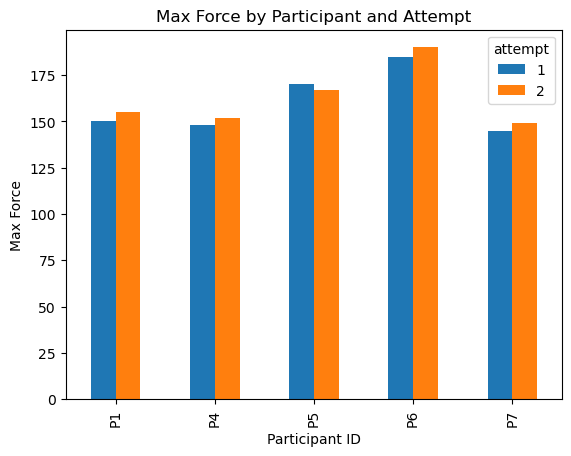

In [65]:
df_chart_trial.plot.bar(
    xlabel='Participant ID',
    ylabel='Max Force',
    title='Max Force by Participant and Attempt')

## MinForce by Participant and Attempt


In [69]:
df_chart_trial_min=df_trial.pivot( index='participantID',
    columns='attempt',
    values='minForce')
df_chart_trial_min


attempt,1,2
participantID,,
P1,50,52
P4,59,49
P5,60,62
P6,70,72
P7,48,50


<Axes: title={'center': 'MinForce by Participant and Attempt'}, xlabel='Participant ID', ylabel='Min Force'>

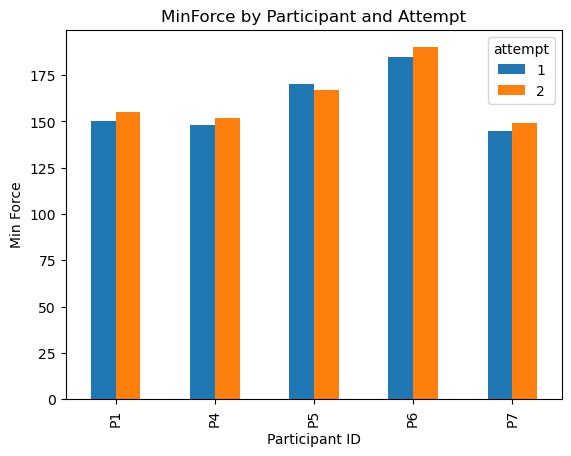

In [71]:
df_chart_trial.plot.bar(
    xlabel='Participant ID',
    ylabel='Min Force',
    title='MinForce by Participant and Attempt')

## AvgForce by Participant and Attempt

In [75]:
df_chart_trial_avg=df_trial.pivot( index='participantID',
    columns='attempt',
    values='avgForce')
df_chart_trial_avg


attempt,1,2
participantID,,
P1,90,93
P4,88,107
P5,108,112
P6,125,128
P7,84,86


<Axes: title={'center': 'AvgForce by Participant and Attempt'}, xlabel='Participant ID', ylabel='Avg Force'>

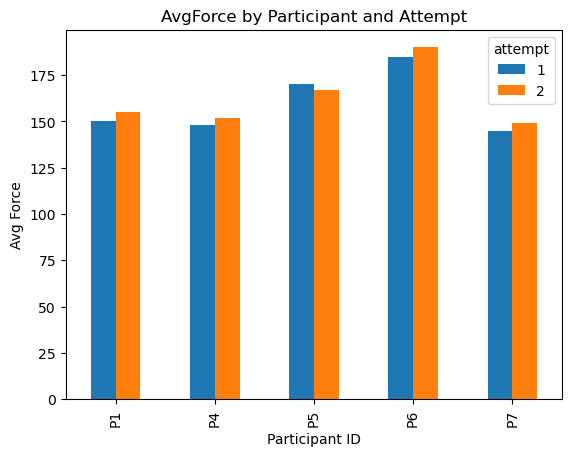

In [77]:
df_chart_trial.plot.bar(
    xlabel='Participant ID',
    ylabel='Avg Force',
    title='AvgForce by Participant and Attempt')

## Join Participant and Trial table

In [81]:
dfJoined = pd.merge(
    df_trial,
    df_participant,
    on="participantID",
    how="inner"
)

In [83]:
dfJoined.head()


,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,name,height,weight,gender,dominantHand,experience,notes
0,T1,P1,1,No music,100,25,5.1,150,50,90,George,72,190.0,Male,R,5,tested in morning
1,T1,P1,2,No music,105,27,5.4,155,52,93,George,72,190.0,Male,R,5,tested in morning
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88,Alex,68,199.0,Male,R,2,NaN
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107,Alex,68,199.0,Male,R,2,NaN
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,Sam,168,185.5,Unknown,L,4,formatting issue


In [85]:
dfJoined['exp'] = pd.cut(
    dfJoined['experience'],
    bins=3,
    labels=("none", "moderate", "expert")
)

In [87]:
dfJoined

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,name,height,weight,gender,dominantHand,experience,notes,exp
0,T1,P1,1,No music,100,25,5.1,150,50,90,George,72,190.0,Male,R,5,tested in morning,expert
1,T1,P1,2,No music,105,27,5.4,155,52,93,George,72,190.0,Male,R,5,tested in morning,expert
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88,Alex,68,199.0,Male,R,2,NaN,none
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107,Alex,68,199.0,Male,R,2,NaN,none
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,Sam,168,185.5,Unknown,L,4,formatting issue,expert
5,T5,P5,2,60-120 BPM,118,32,6.4,167,62,112,Sam,168,185.5,Unknown,L,4,formatting issue,expert
6,T6,P6,1,120+ BPM,125,35,7.0,185,70,125,Chris,70,165.0,Female,R,4,NaN,expert
7,T6,P6,2,120+ BPM,130,36,7.2,190,72,128,Chris,70,165.0,Female,R,4,NaN,expert
8,T7,P7,1,60-120 BPM,99,21,4.9,145,48,84,Taylor,64,135.0,Female,L,1,NaN,none
9,T7,P7,2,60-120 BPM,101,23,5.2,149,50,86,Taylor,64,135.0,Female,L,1,NaN,none


In [89]:
# Group By and Calculate the average of Maxforce

In [91]:
avg_maxforce=dfJoined.groupby(['attempt', 'exp'])['maxForce'].mean().reset_index()

/var/folders/43/2bccxmv52gz_5ft516psrl_80000gn/T/ipykernel_67346/1967420894.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_maxforce=dfJoined.groupby(['attempt', 'exp'])['maxForce'].mean().reset_index()


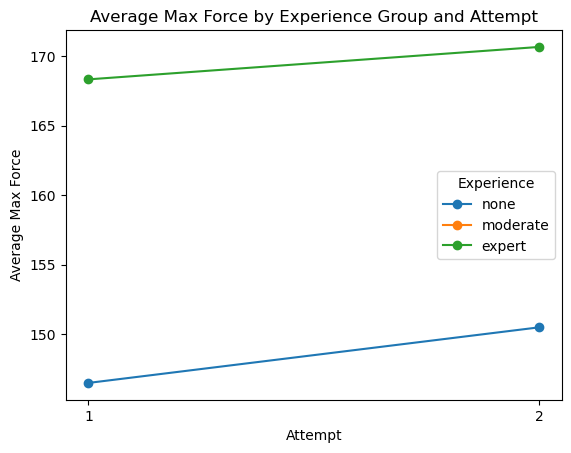

In [93]:
import matplotlib.pyplot as plt

for group in ['none', 'moderate', 'expert']:
    data = avg_maxforce[avg_maxforce['exp'] == group]

    plt.plot(
        data['attempt'],
        data['maxForce'],
        marker='o',
        label=group
    )

plt.xlabel('Attempt')
plt.ylabel('Average Max Force')
plt.title('Average Max Force by Experience Group and Attempt')
plt.xticks([1, 2])
plt.legend(title='Experience')
plt.show()

In [96]:
# create chart line charts using groupby to see how genders performed on given attempts

In [98]:
df_participant_trial= pd.merge(
    df_trial,
    df_participant,
    on="participantID",
    how="inner"
)

In [100]:
df_participant_trial.head()

,trialID,participantID,attempt,bpm,force,totalPunches,accuracy,maxForce,minForce,avgForce,name,height,weight,gender,dominantHand,experience,notes
0,T1,P1,1,No music,100,25,5.1,150,50,90,George,72,190.0,Male,R,5,tested in morning
1,T1,P1,2,No music,105,27,5.4,155,52,93,George,72,190.0,Male,R,5,tested in morning
2,T4,P4,1,<60 BPM,113,22,6.0,148,59,88,Alex,68,199.0,Male,R,2,NaN
3,T4,P4,2,<60 BPM,102,24,5.0,152,49,107,Alex,68,199.0,Male,R,2,NaN
4,T5,P5,1,60-120 BPM,115,29,6.1,170,60,108,Sam,168,185.5,Unknown,L,4,formatting issue


In [102]:
df_box = df_trial.groupby(
    ['participantID', 'attempt', 'maxForce']
).size().reset_index(name='count')

In [104]:
df_box

,participantID,attempt,maxForce,count
0,P1,1,150,1
1,P1,2,155,1
2,P4,1,148,1
3,P4,2,152,1
4,P5,1,170,1
5,P5,2,167,1
6,P6,1,185,1
7,P6,2,190,1
8,P7,1,145,1
9,P7,2,149,1


In [106]:
df_box['max_bins'] = ''

In [108]:
df_box.head()

,participantID,attempt,maxForce,count,max_bins
0,P1,1,150,1,
1,P1,2,155,1,
2,P4,1,148,1,
3,P4,2,152,1,
4,P5,1,170,1,


In [110]:
n = len(df_box)

In [112]:
for i in range(n):
    if df_box.iloc[i]['attempt'] == 2:
        current_max = df_box.iloc[i]['maxForce']
        previous_max = df_box.iloc[i-1]['maxForce']

        if current_max > previous_max:
            df_box.iloc[i, df_box.columns.get_loc('max_bins')] = 'improved'

        elif current_max < previous_max:
            df_box.iloc[i, df_box.columns.get_loc('max_bins')] = 'no improvement'

        else:
            df_box.iloc[i, df_box.columns.get_loc('max_bins')] = 'same'

In [114]:
df_box

,participantID,attempt,maxForce,count,max_bins
0,P1,1,150,1,
1,P1,2,155,1,improved
2,P4,1,148,1,
3,P4,2,152,1,improved
4,P5,1,170,1,
5,P5,2,167,1,no improvement
6,P6,1,185,1,
7,P6,2,190,1,improved
8,P7,1,145,1,
9,P7,2,149,1,improved


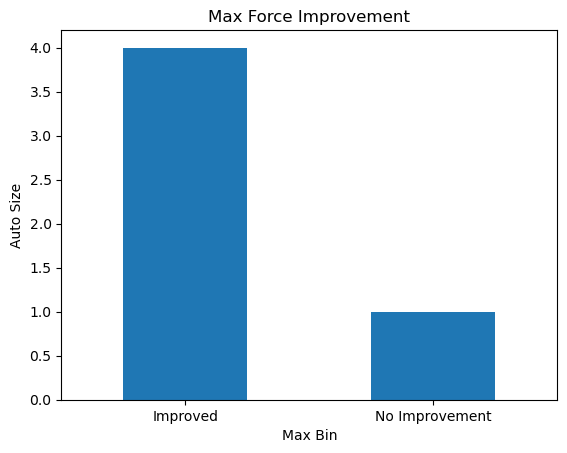

In [116]:
auto_size = df_box['max_bins'].value_counts()
auto_size = auto_size[auto_size.index != '']

chart = auto_size.plot.bar(
    xlabel='Max Bin',
    ylabel='Auto Size',
    title='Max Force Improvement'
)

chart.set_xticks(range(2))
chart.set_xticklabels(['Improved', 'No Improvement'], rotation=0)

plt.show()

In [118]:
df_box['max_bins']

0                  
1          improved
2                  
3          improved
4                  
5    no improvement
6                  
7          improved
8                  
9          improved
Name: max_bins, dtype: object